In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/SBAnational.csv", low_memory=False)
df.shape

(899164, 27)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 899164 entries, 0 to 899163
Data columns (total 27 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   LoanNr_ChkDgt      899164 non-null  int64  
 1   Name               899150 non-null  str    
 2   City               899134 non-null  str    
 3   State              899150 non-null  str    
 4   Zip                899164 non-null  int64  
 5   Bank               897605 non-null  str    
 6   BankState          897598 non-null  str    
 7   NAICS              899164 non-null  int64  
 8   ApprovalDate       899164 non-null  str    
 9   ApprovalFY         899164 non-null  str    
 10  Term               899164 non-null  int64  
 11  NoEmp              899164 non-null  int64  
 12  NewExist           899028 non-null  float64
 13  CreateJob          899164 non-null  int64  
 14  RetainedJob        899164 non-null  int64  
 15  FranchiseCode      899164 non-null  int64  
 16  UrbanRural   

In [3]:
df.head()

,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,...,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,...,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,...,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,...,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"
3,1000044001,"BIG BUCKS PAWN & JEWELRY, LLC",BROKEN ARROW,OK,74012,1ST NATL BK & TR CO OF BROKEN,OK,0,28-Feb-97,1997,...,N,Y,NaN,30-Jun-97,"$35,000.00",$0.00,P I F,$0.00,"$35,000.00","$28,000.00"
4,1000054004,"ANASTASIA CONFECTIONS, INC.",ORLANDO,FL,32801,FLORIDA BUS. DEVEL CORP,FL,0,28-Feb-97,1997,...,N,N,NaN,14-May-97,"$229,000.00",$0.00,P I F,$0.00,"$229,000.00","$229,000.00"


In [4]:
df["MIS_Status"].value_counts(dropna=False)

MIS_Status
P I F     739609
CHGOFF    157558
NaN         1997
Name: count, dtype: int64

In [5]:
df.isnull().sum().sort_values(ascending=False)

ChgOffDate           736465
RevLineCr              4528
LowDoc                 2582
DisbursementDate       2368
MIS_Status             1997
BankState              1566
Bank                   1559
NewExist                136
City                     30
State                    14
Name                     14
Term                      0
ApprovalFY                0
ApprovalDate              0
NAICS                     0
Zip                       0
LoanNr_ChkDgt             0
RetainedJob               0
NoEmp                     0
FranchiseCode             0
UrbanRural                0
CreateJob                 0
DisbursementGross         0
BalanceGross              0
ChgOffPrinGr              0
GrAppv                    0
SBA_Appv                  0
dtype: int64

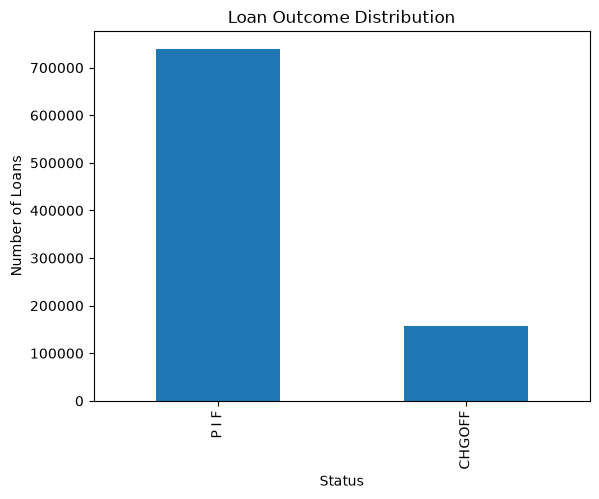

In [6]:
import matplotlib.pyplot as plt
df["MIS_Status"].value_counts().plot(kind="bar")
plt.title("Loan Outcome Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Loans")
plt.savefig("../data/processed/class_balance.png")
plt.show()

In [7]:
df[["Term", "NoEmp", "CreateJob", "RetainedJob"]].describe()

,Term,NoEmp,CreateJob,RetainedJob
count,899164.000000,899164.000000,899164.000000,899164.000000
mean,110.773078,11.411353,8.430376,10.797257
std,78.857305,74.108196,236.688165,237.120600
min,0.000000,0.000000,0.000000,0.000000
25%,60.000000,2.000000,0.000000,0.000000
50%,84.000000,4.000000,0.000000,1.000000
75%,120.000000,10.000000,1.000000,4.000000
max,569.000000,9999.000000,8800.000000,9500.000000


In [8]:
df["DisbursementGross"].head(10)

0     $60,000.00 
1     $40,000.00 
2    $287,000.00 
3     $35,000.00 
4    $229,000.00 
5    $517,000.00 
6    $600,000.00 
7     $45,000.00 
8    $305,000.00 
9     $70,000.00 
Name: DisbursementGross, dtype: str

In [9]:
print(df["RevLineCr"].value_counts(dropna=False))
print()
print(df["LowDoc"].value_counts(dropna=False))

RevLineCr
N      420288
0      257602
Y      201397
T       15284
NaN      4528
1          23
R          14
`          11
2           6
C           2
,           1
3           1
7           1
A           1
5           1
.           1
4           1
-           1
Q           1
Name: count, dtype: int64

LowDoc
N      782822
Y      110335
NaN      2582
0        1491
C         758
S         603
A         497
R          75
1           1
Name: count, dtype: int64


In [10]:
check = pd.read_csv("../data/processed/cleaned_data.csv")
print(check.shape)
check.isnull().sum().sort_values(ascending=False)

C:\Users\nicol\AppData\Local\Temp\ipykernel_17640\922315956.py:1: DtypeWarning: Columns (2: ApprovalFY) have mixed types. Specify dtype option on import or set low_memory=False.
  check = pd.read_csv("../data/processed/cleaned_data.csv")


(896005, 17)


State                12
NAICS                 0
ApprovalFY            0
Term                  0
NoEmp                 0
NewExist              0
CreateJob             0
RetainedJob           0
FranchiseCode         0
UrbanRural            0
RevLineCr             0
LowDoc                0
DisbursementGross     0
GrAppv                0
SBA_Appv              0
NAICS_Sector          0
Default               0
dtype: int64